# **Estimación de la resistencia del concreto mediante regresión lineal**

## **Contexto**

Una empresa productora de concreto quiere mejorar su capacidad para estimar la
resistencia de sus productos. Cuenta con información histórica sobre la
composición de distintas mezclas (cemento, agua, agregados, aditivos) y el
tiempo de curado, y desea aprovecharla para construir modelos que estimen la
resistencia en megapascales (MPa).

## **Pregunta de negocio**

**¿Es posible estimar la resistencia del concreto a partir de la composición de
la mezcla y su tiempo de curado, y cuál de los modelos de regresión lineal
estudiados lo hace mejor?**

## **Datos**

Se utiliza el archivo original `Concrete_Data.xls` del repositorio UCI Machine
Learning Repository (*Concrete Compressive Strength*), descargado del sitio
oficial y guardado en la misma carpeta que este notebook.

> Fuente: I-Cheng Yeh, "Modeling of strength of high performance concrete using
> artificial neural networks," *Cement and Concrete Research*, Vol. 28, No. 12,
> pp. 1797-1808 (1998). Cita requerida por las condiciones de uso del dataset.

## **Estructura del trabajo**

| Parte | Qué se hace | Pregunta que responde |
|---|---|---|
| 1 | Carga y exploración de datos | ¿Qué información contiene el dataset y qué queremos predecir? |
| 2 | Relaciones entre variables | ¿Qué variables se relacionan más con la resistencia? ¿Hay multicolinealidad? |
| 3 | Construcción de modelos | Entrenar OLS, Ridge y Lasso |
| 4 | Evaluación de modelos | ¿Cuál modelo predice mejor? |
| 5 | Conclusiones | ¿Son útiles estos modelos para la empresa? |

---

# Parte 1: **Carga y exploración de datos**

**Objetivo**

Conocer el contenido del dataset antes de construir cualquier modelo: cuántas
mezclas hay, qué mide cada columna, si la información está completa y cómo se
comportan los valores.

**Por qué**

Un modelo de regresión solo es tan bueno como los datos con los que se entrena.
Si no se revisa antes qué contiene el archivo, se corre el riesgo de entrenar
con datos incompletos o de no saber qué variable se está prediciendo.

**Ruta de trabajo**

| Paso | Qué se hace | Qué responde |
|---|---|---|
| 0 | Ubicar el archivo de datos | ¿Dónde están los datos? |
| 1 | Importar librerías | ¿Con qué herramientas se trabaja? |
| 2 | Cargar el dataset y ver los primeros registros | ¿Qué representa una fila? |
| 3 | Dimensiones y tipos de dato | ¿Cuántas mezclas y variables hay? |
| 4 | Valores faltantes | ¿La información está completa? |
| 5 | Estadísticas descriptivas | ¿Cómo se comporta cada variable? |
| 6 | Variable dependiente e independientes | ¿Qué queremos predecir y con qué? |

## Paso 0 — Ubicar el archivo de datos

**Objetivo:** indicar a Python dónde está el archivo.

**Procedimiento:** `Concrete_Data.xls` está en la misma carpeta que el
notebook, por lo que basta con escribir su nombre (ruta relativa).

In [1]:
# =====================================================
# PARTE 1 — PASO 0: Ruta al archivo
# =====================================================

# El archivo está en la misma carpeta que este notebook
RUTA = 'Concrete_Data.xls'

## Paso 1 — Importar librerías

**Objetivo:** cargar las herramientas necesarias para leer y describir los datos.

**Procedimiento:** en esta parte solo se necesita `pandas`. Para leer el
formato `.xls`, pandas usa internamente la librería `xlrd`, que debe estar
instalada aunque no se importe. Las librerías de gráficos y de modelos se
cargan en las partes donde se usan.

In [2]:
# =====================================================
# PARTE 1 — PASO 1: Librerías
# =====================================================

# Tratamiento de datos
import pandas as pd

# Los nombres de las columnas son largos: se muestran todas sin recortar
pd.set_option('display.max_columns', None)

## Paso 2 — Cargar el dataset y ver los primeros registros

**Objetivo:** leer el archivo y observar cómo se ven los datos.

**Procedimiento:** `pd.read_excel()` lee el archivo. De sus tres hojas, solo
`Sheet1` tiene datos, por eso se indica explícitamente. `head()` muestra las
cinco primeras filas.

Los nombres originales de las columnas son largos y están en inglés. Para que
las tablas y el gráfico se lean mejor, se crea un diccionario `nombres_cortos`
que se usa **solo al mostrar** resultados (`rename`). Las columnas de `df` y
las variables de los modelos conservan sus nombres originales. Los siete
componentes se miden en kg por m³ de mezcla.

In [3]:
# =====================================================
# PARTE 1 — PASO 2: Carga del dataset y primeros registros
# =====================================================

# Los datos están en la hoja 'Sheet1'
df = pd.read_excel(RUTA, sheet_name='Sheet1')

# Nombres cortos en español, SOLO para mostrar tablas y gráficos.
# Se emparejan con las columnas originales en el mismo orden.
nombres_cortos = dict(zip(df.columns, [
    'Cemento', 'Escoria', 'Ceniza volante', 'Agua', 'Superplastificante',
    'Agregado grueso', 'Agregado fino', 'Edad (días)', 'Resistencia (MPa)'
]))

# Primeras 5 filas (se muestran con los nombres cortos; df no cambia)
df.head().rename(columns=nombres_cortos)

,Cemento,Escoria,Ceniza volante,Agua,Superplastificante,Agregado grueso,Agregado fino,Edad (días),Resistencia (MPa)
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


**Análisis del resultado:** cada fila es una mezcla de concreto ensayada a una
edad determinada. Las siete primeras columnas son la cantidad de cada
componente, la edad son los días de curado y la última columna es la
resistencia en MPa.

Las filas 2 y 3 tienen la misma composición y solo difieren en la edad (270 y
365 días), con resistencias de 40,27 y 41,05 MPa: una misma mezcla puede
aparecer ensayada a distintas edades.

## Paso 3 — Dimensiones y tipos de dato

**Objetivo:** saber cuántas mezclas y cuántas variables tiene el dataset, y de
qué tipo es cada columna.

**Procedimiento:** `shape` devuelve filas y columnas. `info()` muestra el tipo
de dato de cada columna (`float64` = con decimales, `int64` = entero), que
importa porque los modelos de regresión solo trabajan con columnas numéricas.

In [4]:
# =====================================================
# PARTE 1 — PASO 3: Dimensiones y tipos de dato
# =====================================================

# Cantidad de filas (mezclas) y columnas (variables)
print('Filas y columnas:', df.shape)
print()

# Tipo de dato de cada columna y valores no vacíos
df.info()

Filas y columnas: (1030, 9)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive

**Análisis del resultado:** el dataset tiene **1.030 filas y 9 columnas**, como
indica la fuente oficial de UCI. Todas son numéricas (ocho `float64` y la edad,
`Age (day)`, como `int64`), por lo que no hay que convertir ni codificar ninguna
variable antes de los modelos.

## Paso 4 — Valores faltantes

**Objetivo:** comprobar si la información está completa.

**Procedimiento:** `isnull().sum()` cuenta las celdas vacías por columna y su
porcentaje; los modelos de `scikit-learn` no aceptan celdas vacías. Además se
cuentan los ceros, para no confundir un componente que la mezcla no usó con un
dato que no se anotó.

In [5]:
# =====================================================
# PARTE 1 — PASO 4A: Valores faltantes por variable
# =====================================================

pd.DataFrame({
    'Valores nulos': df.isnull().sum(),
    '% del total': (df.isnull().sum() / len(df) * 100).round(2)
}).rename(index=nombres_cortos)

,Valores nulos,% del total
Cemento,0,0.0
Escoria,0,0.0
Ceniza volante,0,0.0
Agua,0,0.0
Superplastificante,0,0.0
Agregado grueso,0,0.0
Agregado fino,0,0.0
Edad (días),0,0.0
Resistencia (MPa),0,0.0


In [6]:
# =====================================================
# PARTE 1 — PASO 4B: Valores iguales a cero
# =====================================================

# Un cero es un valor registrado, no una celda vacía
pd.DataFrame({
    'Valores en cero': (df == 0).sum(),
    '% del total': ((df == 0).sum() / len(df) * 100).round(2)
}).rename(index=nombres_cortos)

,Valores en cero,% del total
Cemento,0,0.00
Escoria,466,45.24
Ceniza volante,566,54.95
Agua,0,0.00
Superplastificante,379,36.80
Agregado grueso,0,0.00
Agregado fino,0,0.00
Edad (días),0,0.00
Resistencia (MPa),0,0.00


**Análisis del resultado:** **no hay valores faltantes**, así que se trabaja con
las 1.030 mezclas completas, sin eliminar ni rellenar datos.

Hay ceros en tres componentes: escoria (466 mezclas, 45,24 %), ceniza volante
(566, 54,95 %) y superplastificante (379, 36,80 %). Indican que esas
mezclas no incluyeron el componente; no son datos perdidos. Las demás columnas
no tienen ceros.

## Paso 5 — Estadísticas descriptivas

**Objetivo:** resumir cómo se comporta cada variable: su valor típico, su
variabilidad y sus extremos.

**Procedimiento:** `describe()` calcula conteo, media, desviación estándar,
mínimo, percentiles 25, 50 (mediana) y 75, y máximo. `.T` muestra una variable
por fila para leerlo mejor, y los encabezados se traducen al español.

In [7]:
# =====================================================
# PARTE 1 — PASO 5: Estadísticas descriptivas
# =====================================================

# .T muestra una variable por fila; se redondea a 2 decimales
descriptivas = df.describe().T.round(2)

# Encabezados en español y nombres cortos (solo presentación)
descriptivas = descriptivas.rename(
    index=nombres_cortos,
    columns={'count': 'n', 'mean': 'Media', 'std': 'Desv. estándar',
             'min': 'Mínimo', '25%': 'P25', '50%': 'Mediana',
             '75%': 'P75', 'max': 'Máximo'}
)

# El conteo es un número entero de mezclas
descriptivas['n'] = descriptivas['n'].astype(int)

descriptivas

,n,Media,Desv. estándar,Mínimo,P25,Mediana,P75,Máximo
Cemento,1030,281.17,104.51,102.00,192.38,272.90,350.00,540.0
Escoria,1030,73.90,86.28,0.00,0.00,22.00,142.95,359.4
Ceniza volante,1030,54.19,64.00,0.00,0.00,0.00,118.27,200.1
Agua,1030,181.57,21.36,121.75,164.90,185.00,192.00,247.0
Superplastificante,1030,6.20,5.97,0.00,0.00,6.35,10.16,32.2
Agregado grueso,1030,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
Agregado fino,1030,773.58,80.18,594.00,730.95,779.51,824.00,992.6
Edad (días),1030,45.66,63.17,1.00,7.00,28.00,56.00,365.0
Resistencia (MPa),1030,35.82,16.71,2.33,23.71,34.44,46.14,82.6


**Análisis del resultado:**

- **Resistencia:** va de 2,33 a 82,60 MPa, con media de 35,82 y mediana de
  34,44 MPa (próximas). La desviación estándar de 16,71 MPa muestra que las
  resistencias varían bastante entre mezclas: esa variación es la que los
  modelos intentarán explicar.
- **Edad:** de 1 a 365 días. La mediana es 28 días y la media 45,66; el 75 %
  de los registros tiene 56 días o menos, y unos pocos ensayos a edades largas
  elevan el promedio.
- **Cemento:** entre 102 y 540 kg/m³, media de 281,17.
- **Agua:** el componente con menor variación relativa (media 181,57,
  desviación 21,36 kg/m³).
- **Escoria, ceniza volante y superplastificante:** mínimo y percentil 25
  iguales a 0, coherente con el paso 4. En la ceniza volante incluso la mediana
  es 0.
- **Agregados grueso y fino:** los de mayor cantidad (medias de 972,92 y
  773,58 kg/m³).

Las escalas son muy distintas (superplastificante con media 6,20 frente a
972,92 del agregado grueso); esto se retoma en la Parte 3 al escalar las
variables.

## Paso 6 — Variable dependiente e independientes

**Objetivo:** dejar definido qué se quiere predecir y con qué información.

**Procedimiento:** la **variable dependiente (`y`)** es la que se quiere
estimar: la resistencia, última columna. Las **independientes (`X`)** son las
ocho restantes, usadas para hacer la estimación.

La resistencia se selecciona por posición (8, porque Python cuenta desde 0)
porque su nombre original termina con un espacio y es fácil escribirlo mal.

In [8]:
# =====================================================
# PARTE 1 — PASO 6: Identificación de las variables
# =====================================================

# La resistencia es la última columna (posición 8)
columna_objetivo = df.columns[8]

# Variable dependiente (y): lo que queremos predecir
y = df[columna_objetivo]

# Variables independientes (X): todas las demás columnas
X = df.drop(columns=columna_objetivo)

print('Variable dependiente (y):')
print('   ', columna_objetivo)
print()
print('Variables independientes (X):', X.shape[1])
for columna in X.columns:
    print('   ', columna)

Variable dependiente (y):
    Concrete compressive strength(MPa, megapascals) 

Variables independientes (X): 8
    Cement (component 1)(kg in a m^3 mixture)
    Blast Furnace Slag (component 2)(kg in a m^3 mixture)
    Fly Ash (component 3)(kg in a m^3 mixture)
    Water  (component 4)(kg in a m^3 mixture)
    Superplasticizer (component 5)(kg in a m^3 mixture)
    Coarse Aggregate  (component 6)(kg in a m^3 mixture)
    Fine Aggregate (component 7)(kg in a m^3 mixture)
    Age (day)


**Análisis del resultado:** quedan definidas **una variable dependiente** y
**ocho independientes**. `X` e `y` se reutilizarán en la Parte 3 para dividir
los datos en entrenamiento y prueba.

## Respuesta a la pregunta de análisis: **¿Qué información contiene el dataset y qué queremos predecir?**

El dataset contiene **1.030 registros de mezclas de concreto**, cada uno descrito
por **nueve variables numéricas**, sin valores faltantes. Ocho de ellas describen
la mezcla: la cantidad de siete componentes (cemento, escoria de alto horno,
ceniza volante, agua, superplastificante, agregado grueso y agregado fino), en
kg por m³, y la edad del concreto en días al momento del ensayo.

Lo que se quiere predecir es la **resistencia a la compresión del concreto en
MPa**, que en los datos varía entre 2,33 y 82,60 MPa.

Para las siguientes partes se tienen en cuenta dos aspectos: los ceros en
escoria, ceniza volante y superplastificante son datos válidos (mezclas sin ese
componente), y las variables están en escalas muy diferentes.

---

# Parte 2: **Análisis de relaciones entre variables**

**Objetivo**

Identificar qué variables se relacionan más con la resistencia del concreto y
si algunas variables independientes están muy relacionadas entre sí.

**Por qué**

Antes de entrenar los modelos conviene saber qué variables parecen aportar más
información sobre la resistencia. Además, si dos predictoras se mueven casi
siempre juntas, el modelo puede tener dificultad para separar el efecto de cada
una (multicolinealidad).

**Qué es la correlación de Pearson**

Mide la **relación lineal entre dos variables numéricas**, con un valor entre
−1 y 1:

| Valor | Lectura |
|---|---|
| Cercano a 1 | Cuando una aumenta, la otra tiende a aumentar (relación positiva) |
| Cercano a −1 | Cuando una aumenta, la otra tiende a disminuir (relación negativa) |
| Cercano a 0 | No hay una relación lineal clara |

Una correlación indica que dos variables varían juntas, **no que una cause a la
otra**. Además, solo compara las variables de dos en dos.

**Ruta de trabajo**

| Paso | Qué se hace | Qué responde |
|---|---|---|
| 1 | Importar librerías de gráficos | ¿Con qué se construye el mapa de calor? |
| 2 | Matriz de correlación | ¿Cómo se relacionan todas las variables entre sí? |
| 3 | Mapa de calor | ¿Dónde están las relaciones más fuertes, a simple vista? |
| 4 | Correlación con la resistencia | ¿Qué variables tienen mayor relación positiva y negativa con la resistencia? |
| 5 | Correlación entre predictoras | ¿Hay variables independientes muy relacionadas entre sí? |

## Paso 1 — Importar librerías de gráficos

**Objetivo y procedimiento:** se cargan `matplotlib` y `seaborn`, usadas en
clase para construir el mapa de calor.

In [9]:
# =====================================================
# PARTE 2 — PASO 1: Librerías de gráficos
# =====================================================

import matplotlib.pyplot as plt
import seaborn as sns

## Paso 2 — Matriz de correlación

**Objetivo:** obtener la correlación de cada variable con todas las demás.

**Procedimiento:** `corr(method='pearson')` calcula la matriz completa. Cada
celda es la correlación entre la variable de la fila y la de la columna. La
diagonal siempre vale 1 (cada variable consigo misma) y la matriz es simétrica.

In [10]:
# =====================================================
# PARTE 2 — PASO 2: Matriz de correlación
# =====================================================

# Pearson: relación lineal entre cada par de variables
corr_matriz = df.corr(method='pearson')

# Se muestra con nombres cortos en filas y columnas (corr_matriz no cambia)
corr_matriz.rename(index=nombres_cortos, columns=nombres_cortos).round(2)

,Cemento,Escoria,Ceniza volante,Agua,Superplastificante,Agregado grueso,Agregado fino,Edad (días),Resistencia (MPa)
Cemento,1.00,-0.28,-0.40,-0.08,0.09,-0.11,-0.22,0.08,0.50
Escoria,-0.28,1.00,-0.32,0.11,0.04,-0.28,-0.28,-0.04,0.13
Ceniza volante,-0.40,-0.32,1.00,-0.26,0.38,-0.01,0.08,-0.15,-0.11
Agua,-0.08,0.11,-0.26,1.00,-0.66,-0.18,-0.45,0.28,-0.29
Superplastificante,0.09,0.04,0.38,-0.66,1.00,-0.27,0.22,-0.19,0.37
Agregado grueso,-0.11,-0.28,-0.01,-0.18,-0.27,1.00,-0.18,-0.00,-0.16
Agregado fino,-0.22,-0.28,0.08,-0.45,0.22,-0.18,1.00,-0.16,-0.17
Edad (días),0.08,-0.04,-0.15,0.28,-0.19,-0.00,-0.16,1.00,0.33
Resistencia (MPa),0.50,0.13,-0.11,-0.29,0.37,-0.16,-0.17,0.33,1.00


**Análisis del resultado:** la matriz tiene 9 × 9 valores, uno por cada par de
variables. Con tantas cifras es difícil de leer completa; por eso se representa
a continuación con un mapa de calor y luego se extraen las partes que pide la
rúbrica.

## Paso 3 — Mapa de calor

**Objetivo:** visualizar la matriz para localizar rápidamente las relaciones
más fuertes.

**Procedimiento:** `sns.heatmap()` colorea cada celda según su valor, igual que
en clase: rojo para correlaciones positivas, azul para negativas y colores
claros cerca de 0 (`center=0`). `annot=True` escribe el valor en cada celda.
La escala de colores se fija entre −1 y 1 (`vmin`, `vmax`), el rango completo de
Pearson, para que la intensidad del color sea comparable entre celdas.

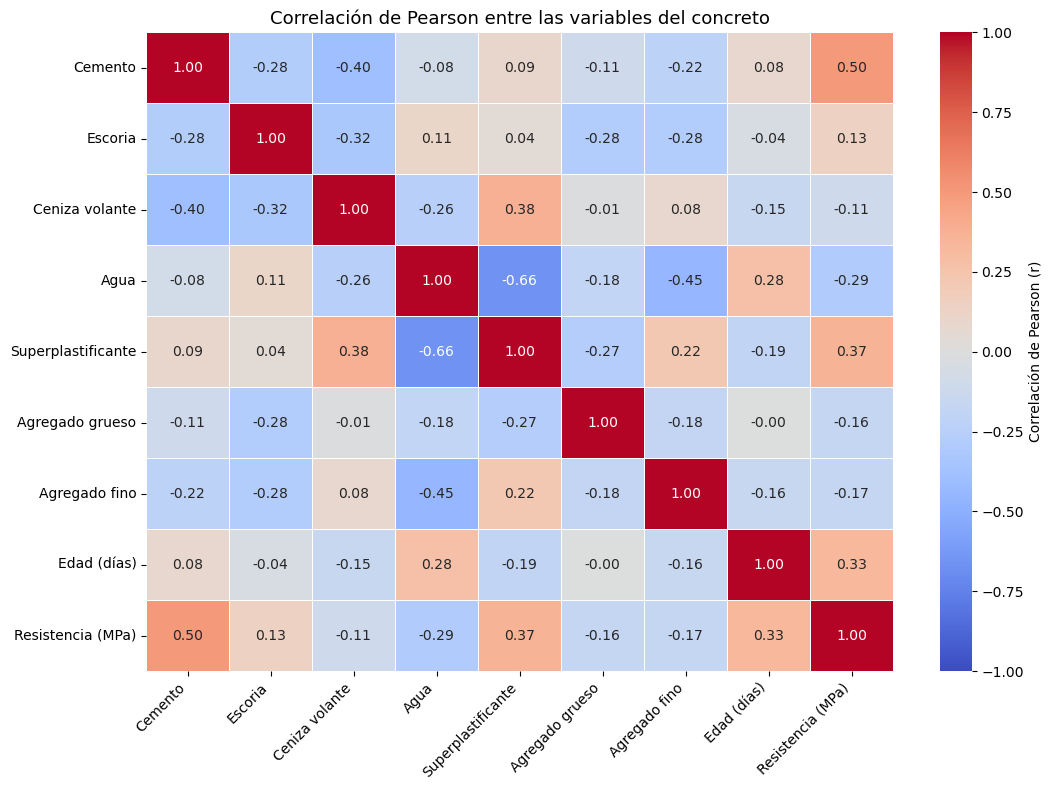

In [11]:
# =====================================================
# PARTE 2 — PASO 3: Mapa de calor
# =====================================================

# Copia de la matriz con nombres cortos, solo para las etiquetas del gráfico
corr_grafico = corr_matriz.rename(index=nombres_cortos, columns=nombres_cortos)

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(
    corr_grafico,
    annot=True, fmt='.2f',                      # valor escrito en cada celda
    cmap='coolwarm', center=0,                  # azul negativo, rojo positivo
    vmin=-1, vmax=1,                            # escala completa de Pearson
    linewidths=0.5, linecolor='white',          # separación entre celdas
    cbar_kws={'label': 'Correlación de Pearson (r)'},
    ax=ax
)
ax.set_title('Correlación de Pearson entre las variables del concreto', fontsize=13)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Análisis del resultado:** la mayoría de las celdas tiene colores claros, es
decir, correlaciones cercanas a 0. Los tonos más intensos fuera de la diagonal
aparecen en la fila de la resistencia y en el cruce de agua con
superplastificante; se cuantifican en los pasos 4 y 5.

## Paso 4 — Correlación de cada variable con la resistencia

**Objetivo:** identificar las variables con mayor correlación positiva y
negativa con la resistencia.

**Procedimiento:** se toma la columna de la resistencia de la matriz, se quita
la correlación de la resistencia consigo misma (`drop`) y se ordena de mayor a
menor, como en el notebook de clase.

In [12]:
# =====================================================
# PARTE 2 — PASO 4: Correlación con la resistencia
# =====================================================

# Columna de la resistencia, sin su correlación consigo misma, ordenada
corr_resistencia = corr_matriz[columna_objetivo].drop(columna_objetivo).sort_values(ascending=False)

# Se muestra como tabla, con nombres cortos
corr_resistencia.rename(index=nombres_cortos).to_frame('Correlación con la resistencia').round(2)

,Correlación con la resistencia
Cemento,0.50
Superplastificante,0.37
Edad (días),0.33
Escoria,0.13
Ceniza volante,-0.11
Agregado grueso,-0.16
Agregado fino,-0.17
Agua,-0.29


**Análisis del resultado:**

- **Correlaciones positivas:** el **cemento** tiene la mayor (0,50), seguido del
  **superplastificante** (0,37) y la **edad** (0,33). La escoria tiene una
  correlación positiva baja (0,13). En los datos, las mezclas con más cemento,
  más superplastificante o mayor edad tienden a presentar mayor resistencia.
- **Correlaciones negativas:** el **agua** tiene la mayor en magnitud (−0,29).
  Le siguen el agregado fino (−0,17), el agregado grueso (−0,16) y la ceniza
  volante (−0,11), todas cercanas a 0. Las mezclas con más agua tienden a
  presentar menor resistencia.

Ninguna variable supera 0,50 en valor absoluto con la resistencia.

## Paso 5 — Correlación entre las variables independientes

**Objetivo:** comprobar si hay variables independientes muy correlacionadas
entre sí.

**Procedimiento:** se calcula la matriz solo con las variables de `X`, para
revisar las relaciones entre predictoras sin la resistencia.

In [13]:
# =====================================================
# PARTE 2 — PASO 5: Correlación entre predictoras
# =====================================================

# Solo las 8 variables independientes (se muestran con nombres cortos)
X.corr(method='pearson').rename(index=nombres_cortos, columns=nombres_cortos).round(2)

,Cemento,Escoria,Ceniza volante,Agua,Superplastificante,Agregado grueso,Agregado fino,Edad (días)
Cemento,1.00,-0.28,-0.40,-0.08,0.09,-0.11,-0.22,0.08
Escoria,-0.28,1.00,-0.32,0.11,0.04,-0.28,-0.28,-0.04
Ceniza volante,-0.40,-0.32,1.00,-0.26,0.38,-0.01,0.08,-0.15
Agua,-0.08,0.11,-0.26,1.00,-0.66,-0.18,-0.45,0.28
Superplastificante,0.09,0.04,0.38,-0.66,1.00,-0.27,0.22,-0.19
Agregado grueso,-0.11,-0.28,-0.01,-0.18,-0.27,1.00,-0.18,-0.00
Agregado fino,-0.22,-0.28,0.08,-0.45,0.22,-0.18,1.00,-0.16
Edad (días),0.08,-0.04,-0.15,0.28,-0.19,-0.00,-0.16,1.00


**Análisis del resultado:** las correlaciones más altas entre predictoras son:

| Par de variables | Correlación |
|---|---|
| Agua – Superplastificante | −0,66 |
| Agua – Agregado fino | −0,45 |
| Cemento – Ceniza volante | −0,40 |
| Ceniza volante – Superplastificante | 0,38 |

Entre **agua y superplastificante (−0,66)** existe una **relación inversa
apreciable**: en estas mezclas, cuando se usa más superplastificante, tiende a
usarse menos agua. El resto de pares tiene valores más bajos.

Esta revisión solo compara variables de dos en dos, por lo que permite señalar
pares relacionados, pero no basta para concluir sobre la multicolinealidad del
conjunto.

## Respuesta a la pregunta de análisis

**¿Cuáles variables parecen estar más relacionadas con la resistencia del concreto?**

El **cemento** (0,50), el **superplastificante** (0,37) y la **edad** (0,33)
tienen las correlaciones positivas más altas con la resistencia, y el **agua**
(−0,29) la negativa más alta. Las demás variables presentan correlaciones
cercanas a 0. Estas relaciones indican asociación en los datos, no que una
variable cause el cambio en la resistencia.

**¿Existen posibles problemas de multicolinealidad?**

La correlación más alta entre predictoras es la de agua y superplastificante
(−0,66), una relación inversa apreciable que indica una posible fuente de
multicolinealidad. Como la matriz solo compara variables de dos en dos, no
permite descartar ni confirmar una multicolinealidad grave; este par se tendrá
presente al comparar OLS con Ridge y Lasso.

---

# Parte 3: **Construcción de modelos**

**Objetivo**

Entrenar tres modelos de regresión lineal para estimar la resistencia del
concreto: OLS, Ridge y Lasso.

**Por qué**

Los tres buscan una ecuación lineal que relacione las ocho variables
independientes con la resistencia, pero difieren en cómo calculan los
coeficientes:

| Modelo | Cómo calcula los coeficientes |
|---|---|
| **OLS** (mínimos cuadrados ordinarios) | Minimiza la suma de los errores al cuadrado, sin penalización |
| **Ridge** | Como OLS, con una penalización que reduce los coeficientes (L2) |
| **Lasso** | Como OLS, con una penalización que puede llevar coeficientes a cero (L1) |

En Ridge y Lasso, `alpha` controla la intensidad de la penalización; la rúbrica
fija `alpha = 1.0` para ambos.

**Alcance**

En esta parte solo se dividen los datos y se entrenan los modelos. Las
predicciones y métricas se calculan en la Parte 4.

**Ruta de trabajo**

| Paso | Qué se hace | Qué responde |
|---|---|---|
| 1 | Importar librerías de modelado | ¿Con qué herramientas se entrenan los modelos? |
| 2 | Dividir en entrenamiento y prueba | ¿Con qué datos aprende el modelo y con cuáles se evalúa? |
| 3 | Entrenar OLS | Modelo 1 |
| 4 | Escalar las variables | ¿Cómo se preparan los datos para Ridge y Lasso? |
| 5 | Entrenar Ridge | Modelo 2 |
| 6 | Entrenar Lasso | Modelo 3 |

## Paso 1 — Importar librerías de modelado

**Objetivo y procedimiento:** se cargan desde `scikit-learn` la función para
dividir los datos, el escalador y los tres modelos. `train_test_split`,
`StandardScaler` y `Ridge` se usaron en clase; `LinearRegression` y `Lasso` se
incorporan porque la rúbrica los pide y se usan del mismo modo que `Ridge`
(`.fit()` para entrenar y `.predict()` para predecir).

In [14]:
# =====================================================
# PARTE 3 — PASO 1: Librerías de modelado
# =====================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso

## Paso 2 — División en entrenamiento y prueba

**Objetivo:** separar los datos con los que aprenden los modelos de los datos
con los que se evaluarán.

**Procedimiento:** `train_test_split` reparte las filas al azar: el 80 %
(`train_size=0.8`) para entrenamiento y el 20 % para prueba. `random_state=42`
fija ese reparto, de modo que siempre se obtiene la misma división y los tres
modelos se entrenan y evalúan con exactamente las mismas mezclas.

In [15]:
# =====================================================
# PARTE 3 — PASO 2: División 80 / 20
# =====================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.8,
    random_state=42
)

print('Entrenamiento:', X_train.shape, y_train.shape)
print('Prueba       :', X_test.shape, y_test.shape)

Entrenamiento: (824, 8) (824,)
Prueba       : (206, 8) (206,)


**Análisis del resultado:** de las 1.030 mezclas, **824 quedan para
entrenamiento** y **206 para prueba**, cada una con sus 8 variables
independientes.

## Paso 3 — Modelo 1: Regresión lineal (OLS)

**Objetivo:** entrenar el modelo de mínimos cuadrados ordinarios.

**Procedimiento:** se crea el modelo con `LinearRegression()` y se entrena con
`.fit()` usando las **variables originales, sin escalar**. Ridge y Lasso, en
cambio, utilizarán los datos escalados, conforme a la rúbrica.

In [16]:
# =====================================================
# PARTE 3 — PASO 3: Modelo OLS
# =====================================================

modelo_ols = LinearRegression()

# Entrenamiento con los datos originales (sin escalar)
modelo_ols.fit(X_train, y_train)

print('Modelo OLS entrenado')

Modelo OLS entrenado


**Análisis del resultado:** el modelo OLS quedó entrenado con las 824 mezclas
de entrenamiento.

## Paso 4 — Escalamiento de las variables para Ridge y Lasso

**Objetivo:** expresar todas las variables independientes en una escala común.

**Por qué:** la penalización de Ridge y Lasso depende del tamaño de los
coeficientes, y ese tamaño depende de las unidades de cada variable. Como se vio
en la Parte 1, las escalas son muy distintas (superplastificante con media 6,20
y agregado grueso con 972,92 kg/m³). Sin escalar, la penalización afectaría de
forma desigual a las variables solo por sus unidades.

**Procedimiento:** `StandardScaler` resta a cada variable su media y la divide
por su desviación estándar.

- `fit_transform(X_train)`: **aprende** la media y la desviación **solo del
  entrenamiento** y transforma esos datos.
- `transform(X_test)`: aplica a la prueba lo ya aprendido, **sin volver a
  ajustar**.

La prueba representa mezclas nuevas que el modelo no ha visto. Si el escalador
aprendiera también de ellas, información de la prueba pasaría al entrenamiento
y la evaluación de la Parte 4 dejaría de ser justa.

In [17]:
# =====================================================
# PARTE 3 — PASO 4: Escalamiento (ajustado solo con entrenamiento)
# =====================================================

scaler = StandardScaler()

# Aprende media y desviación SOLO del entrenamiento y lo transforma
X_train_esc = scaler.fit_transform(X_train)

# La prueba se transforma con lo aprendido del entrenamiento (sin volver a ajustar)
X_test_esc = scaler.transform(X_test)

## Paso 5 — Modelo 2: Regresión Ridge

**Objetivo:** entrenar el modelo con regularización Ridge.

**Procedimiento:** se crea `Ridge(alpha=1.0)` y se entrena con los datos de
entrenamiento **escalados**.

In [18]:
# =====================================================
# PARTE 3 — PASO 5: Modelo Ridge
# =====================================================

modelo_ridge = Ridge(alpha=1.0)

# Entrenamiento con los datos escalados
modelo_ridge.fit(X_train_esc, y_train)

print('Modelo Ridge entrenado')

Modelo Ridge entrenado


## Paso 6 — Modelo 3: Regresión Lasso

**Objetivo:** entrenar el modelo con regularización Lasso.

**Procedimiento:** se crea `Lasso(alpha=1.0)` y se entrena con los mismos datos
escalados que Ridge.

In [19]:
# =====================================================
# PARTE 3 — PASO 6: Modelo Lasso
# =====================================================

modelo_lasso = Lasso(alpha=1.0)

# Entrenamiento con los datos escalados
modelo_lasso.fit(X_train_esc, y_train)

print('Modelo Lasso entrenado')

Modelo Lasso entrenado


## Resumen de la Parte 3

| Modelo | Datos de entrenamiento | Parámetro |
|---|---|---|
| OLS (`modelo_ols`) | `X_train` (sin escalar) | — |
| Ridge (`modelo_ridge`) | `X_train_esc` (escalado) | `alpha = 1.0` |
| Lasso (`modelo_lasso`) | `X_train_esc` (escalado) | `alpha = 1.0` |

En la Parte 4 se evaluarán con `X_test` (OLS) y `X_test_esc` (Ridge y Lasso).

---

# Parte 4: **Evaluación de modelos**

**Objetivo**

Medir qué tan bien predice cada modelo la resistencia de mezclas que no vio
durante el entrenamiento, y compararlos.

**Por qué**

Un modelo es útil para la empresa si acierta con mezclas nuevas, no solo con las
que usó para aprender. Por eso los tres se evalúan sobre las mismas 206 mezclas
de prueba.

**Métricas utilizadas**

**R² (coeficiente de determinación):** proporción de la variación de la
resistencia que el modelo explica. Cuanto más cerca de 1, mejor.

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

**RMSE (raíz del error cuadrático medio):** resume la magnitud de los errores,
en MPa, y penaliza más los errores grandes. Cuanto más bajo, mejor.

$$RMSE = \sqrt{\frac{1}{n}\sum (y_i - \hat{y}_i)^2}$$

Donde $y_i$ es la resistencia real, $\hat{y}_i$ la predicha y $\bar{y}$ la
media de las resistencias reales.

**Ruta de trabajo**

| Paso | Qué se hace | Qué responde |
|---|---|---|
| 1 | Importar las funciones de métricas | ¿Con qué se calculan R² y RMSE? |
| 2 | Predicciones sobre la prueba | ¿Qué resistencia estima cada modelo? |
| 3 | Calcular R² | ¿Qué proporción de la variación explica cada modelo? |
| 4 | Calcular RMSE | ¿Cuánto se equivoca cada modelo, en MPa? |
| 5 | Tabla comparativa | ¿Cuál modelo tiene el mejor rendimiento? |

## Paso 1 — Importar las funciones de métricas

**Objetivo y procedimiento:** se cargan `r2_score` y `mean_squared_error`, como
en clase, y `numpy` para calcular la raíz cuadrada del error cuadrático medio.

In [20]:
# =====================================================
# PARTE 4 — PASO 1: Librerías de métricas
# =====================================================

import numpy as np
from sklearn.metrics import r2_score, mean_squared_error

## Paso 2 — Predicciones sobre los datos de prueba

**Objetivo:** obtener la resistencia estimada por cada modelo para las 206
mezclas de prueba.

**Procedimiento:** se usa `.predict()`; cada modelo recibe los datos en el mismo
formato con que fue entrenado. Se muestran las primeras filas junto al valor
real.

In [21]:
# =====================================================
# PARTE 4 — PASO 2: Predicciones
# =====================================================

pred_ols = modelo_ols.predict(X_test)        # datos originales
pred_ridge = modelo_ridge.predict(X_test_esc)  # datos escalados
pred_lasso = modelo_lasso.predict(X_test_esc)  # datos escalados

# Valor real y predicciones de los tres modelos, primeras 5 mezclas de prueba
# (el índice es el número de fila de la mezcla en el dataset original)
pd.DataFrame({
    'Resistencia real (MPa)': y_test,
    'OLS (MPa)': pred_ols,
    'Ridge (MPa)': pred_ridge,
    'Lasso (MPa)': pred_lasso
}).rename_axis('Fila en el dataset').head().round(2)

,Resistencia real (MPa),OLS (MPa),Ridge (MPa),Lasso (MPa)
Fila en el dataset,,,,
31,52.91,59.66,59.66,55.62
109,55.90,52.04,51.97,48.84
136,74.50,63.52,63.52,60.85
88,35.30,51.57,51.50,48.48
918,10.54,17.22,17.24,19.23


**Análisis del resultado:** cada modelo generó una predicción para cada mezcla
de prueba. En estas cinco filas, OLS y Ridge dan valores casi idénticos, mientras
que Lasso se separa más de ellos. Los aciertos varían según la mezcla: por
ejemplo, para una resistencia real de 55,90 MPa, OLS estima 52,04 MPa; para una
de 35,30 MPa, estima 51,57 MPa. Para comparar los modelos en conjunto se usan
las métricas de los pasos siguientes.

## Paso 3 — Coeficiente de determinación (R²)

**Objetivo:** medir qué proporción de la variación de la resistencia explica
cada modelo.

**Procedimiento:** `r2_score(valores_reales, predicciones)` para cada modelo.
Se muestran 4 decimales porque, como se verá, algunas diferencias son muy
pequeñas.

In [22]:
# =====================================================
# PARTE 4 — PASO 3: R²
# =====================================================

r2_ols = r2_score(y_test, pred_ols)
r2_ridge = r2_score(y_test, pred_ridge)
r2_lasso = r2_score(y_test, pred_lasso)

print('R² OLS  :', round(r2_ols, 4))
print('R² Ridge:', round(r2_ridge, 4))
print('R² Lasso:', round(r2_lasso, 4))

R² OLS  : 0.6275
R² Ridge: 0.6276
R² Lasso: 0.5639


**Análisis del resultado:** OLS (0,6275) y Ridge (0,6276) explican alrededor del
63 % de la variación de la resistencia en las mezclas de prueba. Lasso (0,5639)
explica alrededor del 56 %.

## Paso 4 — Raíz del error cuadrático medio (RMSE)

**Objetivo:** resumir la magnitud de los errores de cada modelo, en MPa.

**Procedimiento:** como en clase, se calcula `mean_squared_error` y se le
aplica la raíz cuadrada con `np.sqrt()`, para volver a las unidades de la
resistencia (MPa).

In [23]:
# =====================================================
# PARTE 4 — PASO 4: RMSE
# =====================================================

rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))
rmse_ridge = np.sqrt(mean_squared_error(y_test, pred_ridge))
rmse_lasso = np.sqrt(mean_squared_error(y_test, pred_lasso))

print('RMSE OLS  :', round(rmse_ols, 4), 'MPa')
print('RMSE Ridge:', round(rmse_ridge, 4), 'MPa')
print('RMSE Lasso:', round(rmse_lasso, 4), 'MPa')

RMSE OLS  : 9.7967 MPa
RMSE Ridge: 9.7964 MPa
RMSE Lasso: 10.6008 MPa


**Análisis del resultado:** el RMSE de OLS y Ridge es de unos 9,80 MPa
(9,7967 y 9,7964), y el de Lasso de unos 10,60 MPa (10,6008).

## Paso 5 — Tabla comparativa y mejor modelo

**Objetivo:** reunir los resultados en una sola tabla e identificar el modelo
con mejor rendimiento predictivo.

**Procedimiento:** se construye un `DataFrame` con una fila por modelo y se
ordena de mayor a menor R². El mejor modelo es el de **mayor R² y menor RMSE**.

In [24]:
# =====================================================
# PARTE 4 — PASO 5: Tabla comparativa
# =====================================================

comparacion = pd.DataFrame({
    'Modelo': ['OLS', 'Ridge (alpha=1.0)', 'Lasso (alpha=1.0)'],
    'R²': [r2_ols, r2_ridge, r2_lasso],
    'RMSE (MPa)': [rmse_ols, rmse_ridge, rmse_lasso]
})

# Ordenada de mejor a peor según R², con el nombre del modelo como índice
comparacion.sort_values('R²', ascending=False).set_index('Modelo').round(4)

,R²,RMSE (MPa)
Modelo,,
Ridge (alpha=1.0),0.6276,9.7964
OLS,0.6275,9.7967
Lasso (alpha=1.0),0.5639,10.6008


**Análisis del resultado:**

- **Ridge** obtuvo el mejor rendimiento: el R² más alto (0,6276) y el RMSE más
  bajo (9,7964 MPa).
- Su ventaja sobre **OLS** es mínima: 0,00002 en R² y 0,0003 MPa en RMSE. Con
  dos decimales ambos muestran los mismos valores (R² de 0,63 y RMSE de
  9,80 MPa): una diferencia sin relevancia práctica apreciable en esta
  evaluación.
- **Lasso** quedó claramente por debajo: su R² es 0,0637 menor que el de Ridge y
  su RMSE es 0,80 MPa mayor.

---

# Parte 5: **Conclusiones**

Las respuestas se basan únicamente en los resultados obtenidos en las partes
anteriores de este notebook.

## 1. ¿Cuál de los tres modelos obtuvo el mejor resultado y por qué?

En términos numéricos, el mejor modelo fue **Ridge (alpha = 1.0)**, porque
obtuvo el R² más alto (0,6276) y el RMSE más bajo (9,7964 MPa) sobre las mismas
206 mezclas de prueba.

Sin embargo, su ventaja frente a OLS es mínima: 0,00002 en R² y 0,0003 MPa en
RMSE. Con dos decimales ambos modelos presentan los mismos valores, por lo que
se trata de una **diferencia sin relevancia práctica apreciable en esta
evaluación**. Lasso fue el modelo con el resultado más bajo.

## 2. ¿Qué significa el valor de R² obtenido por el mejor modelo?

El R² de Ridge es 0,6276. Significa que el modelo explica aproximadamente el
**63 % de la variabilidad de la resistencia** del concreto en las mezclas del
conjunto de prueba. El 37 % restante de esa variabilidad no queda explicado por
el modelo.

## 3. ¿Qué representa el RMSE en el contexto de la resistencia del concreto?

El RMSE de Ridge es 9,7964 MPa. Es un valor que **resume la magnitud de los
errores** de predicción en las 206 mezclas de prueba, expresado en las mismas
unidades que la resistencia. Como eleva los errores al cuadrado antes de
promediarlos, **penaliza más los errores grandes**.

No indica cuánto se equivoca el modelo en cada mezcla: los errores individuales
pueden ser menores o mayores. Por ejemplo, en las primeras mezclas de prueba
(Parte 4, paso 2), Ridge estimó 59,66 MPa para una mezcla de 52,91 MPa
(diferencia de 6,75 MPa) y 51,50 MPa para una de 35,30 MPa (diferencia de
16,20 MPa).

Como referencia, en el dataset la resistencia tiene una media de 35,82 MPa y
varía entre 2,33 y 82,60 MPa (Parte 1).

## 4. ¿Qué diferencias encontró entre OLS, Ridge y Lasso?

**Diferencias teóricas:**

- **OLS** calcula los coeficientes minimizando la suma de los errores al
  cuadrado, sin ninguna penalización; se entrenó con las variables originales.
- **Ridge** agrega una penalización que reduce el tamaño de los coeficientes,
  sin llevarlos a cero.
- **Lasso** agrega una penalización que puede llevar algunos coeficientes
  exactamente a cero, lo que equivale a dejar fuera algunas variables.
- Ridge y Lasso se entrenaron con los datos escalados (Parte 3, paso 4).

**Resultados observados:**

- OLS y Ridge obtuvieron resultados prácticamente iguales (R² de 0,6275 y
  0,6276; RMSE de 9,7967 y 9,7964 MPa), y sus predicciones individuales también
  fueron casi idénticas.
- Lasso obtuvo un R² menor (0,5639) y un RMSE mayor (10,6008 MPa).
- En la Parte 2 se observó una relación inversa apreciable entre agua y
  superplastificante (−0,66). Aun así, en estos resultados la regularización de
  Ridge no produjo una mejora apreciable frente a OLS.

Como en este trabajo no se analizaron los coeficientes de los modelos, los
resultados no permiten determinar qué coeficientes redujo o eliminó Lasso ni la
causa concreta de su menor rendimiento. Solo muestran que, con `alpha = 1.0`,
su desempeño en este conjunto de prueba fue inferior al de OLS y Ridge.

## 5. ¿Considera que estos modelos podrían resultar útiles para la empresa?

Los modelos OLS y Ridge podrían ser útiles como **herramienta de apoyo** para
obtener una estimación inicial de la resistencia a partir de la composición de la
mezcla y su edad, ya que explican aproximadamente el 63 % de la variabilidad de
la resistencia en mezclas que no se usaron para entrenarlos.

Sin embargo, sus resultados tienen limitaciones que la empresa debería
considerar:

- Alrededor del 37 % de la variabilidad de la resistencia no queda explicado.
- El RMSE es de unos 9,8 MPa, y en mezclas individuales el error puede ser
  mayor, como en el caso de 16,20 MPa visto en la pregunta 3.
- La evaluación se realizó con una sola división de los datos (80/20).
- Los modelos se construyeron con las mezclas de este dataset, por lo que sus
  estimaciones solo tienen respaldo dentro de rangos de composición y edad
  similares a los observados.

Por estas razones, las estimaciones de los modelos no sustituyen los ensayos de
laboratorio ni garantizan la resistencia de una mezcla; podrían servir como
referencia previa, que luego debe confirmarse con los ensayos correspondientes.